**TAREA 3: APRENDIZAJE NO SUPERVISADO**
-

A lo largo de este notebook se desarrolla la tarea de aprendizaje no supervisado del proyecto. El objetivo es identificar perfiles de estudiantes, patrones o estructuras relevantes en los datos.

No se trata de recuperar exactamente las clases de la variable objetivo, sino de descubrir agrupaciones que aporten información útil para interpretar mejor el fenómeno del abandono y del éxito académico.

El enfoque será: primero seleccionar un subconjunto razonado de variables, después aplicar PCA para reducir la dimensión y visualizar la estructura de los datos, y finalmente aplicar clustering para identificar perfiles y caracterizarlos.

**1. Carga de datos**

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import warnings
warnings.filterwarnings("ignore")

from data_loading import cargar_dataset
from preprocessing import construir_preprocesador
from unsupervised import obtener_vars_no_supervisado, evaluar_rango_k, analisis_estabilidad

df = cargar_dataset("../rendimiento_estudiantes.csv")
df.head()

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


**2. Selección del subconjunto razonado de variables**

Para aplicar las técnicas de aprendizaje no supervisado, selecciono variables que describen el perfil del estudiante y su desempeño temprano, excluyendo los targets y las variables del segundo semestre. La idea es buscar perfiles académicos tempranos y luego ver si esos perfiles se relacionan con la trayectoria final del estudiante, sin haber usado esa información para construirlos.

Las variables seleccionadas son:
- Perfil del estudiante: edad, género, desplazado, internacional.
- Acceso y contexto: nota de admisión, nota de cualificación previa, orden de solicitud.
- Situación administrativa: deudor, matrícula al día, becado.
- Rendimiento del primer semestre: asignaturas matriculadas, evaluadas, aprobadas, nota media, asignaturas sin evaluación.
- Macroeconómicas: tasa de desempleo, inflación, PIB.

Excluyo las variables con demasiadas categorías (ocupación madre/padre, cualificación madre/padre, nacionalidad, modo de solicitud, curso, cualificación previa) porque generarían un número excesivo de datos que realmente no aportan mucho que dominarían el PCA y el clustering de forma artificial. También excluyo asistencia diurna/vespertina y necesidades educativas especiales por tener muy poca variabilidad.

In [2]:
#obtengo las variables desde src
vars_numericas_ns, vars_categoricas_ns = obtener_vars_no_supervisado()

print(f"Variables numéricas: {len(vars_numericas_ns)}"
	  f"\nVariables categóricas: {len(vars_categoricas_ns)}"
	  f"\nTotal: {len(vars_numericas_ns) + len(vars_categoricas_ns)}")

Variables numéricas: 13
Variables categóricas: 6
Total: 19


**3. Preprocesado**

Estandarizo las variables numéricas, aspecto clave para aplicar PCA posteriormente, y codifico las categóricas con one-hot al construir el preprocesado. La estandarización es especialmente importante para PCA y clustering, ya que ambos métodos son sensibles a la escala de las variables.

In [3]:
#preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), vars_numericas_ns),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), vars_categoricas_ns)
    ]
)

X_ns = df[vars_numericas_ns + vars_categoricas_ns]
X_scaled = preprocesador.fit_transform(X_ns)

#obtengo los nombres de las columnas resultantes
nombres_num = vars_numericas_ns
nombres_cat = preprocesador.transformers_[1][1].get_feature_names_out(vars_categoricas_ns).tolist()
nombres_cols = nombres_num + nombres_cat

print(f"Dimension del dataset preprocesado: {X_scaled.shape}"
	  f"\nVariables resultantes: {len(nombres_cols)}")

Dimension del dataset preprocesado: (4424, 19)
Variables resultantes: 19


**4. PCA: reducción de dimensión**

Aplico PCA para entender la estructura global de los datos y visualizar si existe alguna separación natural entre grupos de estudiantes. PCA busca las direcciones de mayor variabilidad en los datos y permite representarlos en pocas dimensiones sin perder demasiada información.

In [4]:
#PCA con todas las componentes para estudiar la varianza explicada
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

varianza_explicada = pca_full.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

print("Varianza explicada por componente: ")
for i in range(min(10, len(varianza_explicada))):
    print(f" - PC{i+1}: {varianza_explicada[i]:.3f} (acum: {varianza_acumulada[i]:.3f})")

Varianza explicada por componente: 
 - PC1: 0.238 (acum: 0.238)
 - PC2: 0.122 (acum: 0.360)
 - PC3: 0.117 (acum: 0.476)
 - PC4: 0.091 (acum: 0.567)
 - PC5: 0.078 (acum: 0.646)
 - PC6: 0.074 (acum: 0.720)
 - PC7: 0.057 (acum: 0.777)
 - PC8: 0.048 (acum: 0.825)
 - PC9: 0.041 (acum: 0.866)
 - PC10: 0.032 (acum: 0.897)


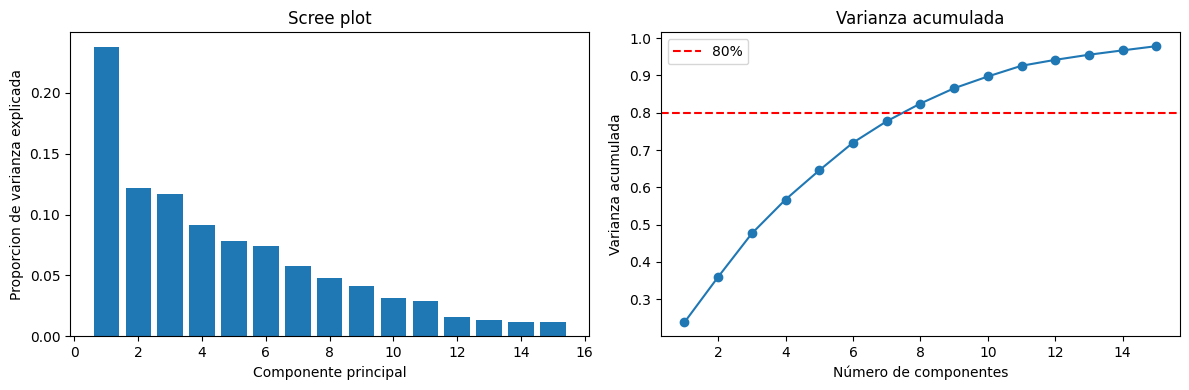

In [5]:
#scree plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

n_mostrar = min(15, len(varianza_explicada))
axes[0].bar(range(1, n_mostrar+1), varianza_explicada[:n_mostrar])
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Proporcion de varianza explicada")
axes[0].set_title("Scree plot")

axes[1].plot(range(1, n_mostrar+1), varianza_acumulada[:n_mostrar], marker="o")
axes[1].axhline(y=0.8, color="red", linestyle="--", label="80%")
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada")
axes[1].set_title("Varianza acumulada")
axes[1].legend()

plt.tight_layout()
plt.show()

El scree plot y la varianza acumulada me ayudan a decidir cuántas componentes retener. Busco el punto en el que añadir más componentes aporta poco.

**5. Visualización en 2D con PCA**

Proyecto las observaciones sobre las dos primeras componentes principales para ver si existe alguna estructura visible. Coloreo los puntos según la variable objetivo (que no se ha usado para construir el PCA) para ver si hay relación entre la estructura descubierta y la trayectoria del estudiante.

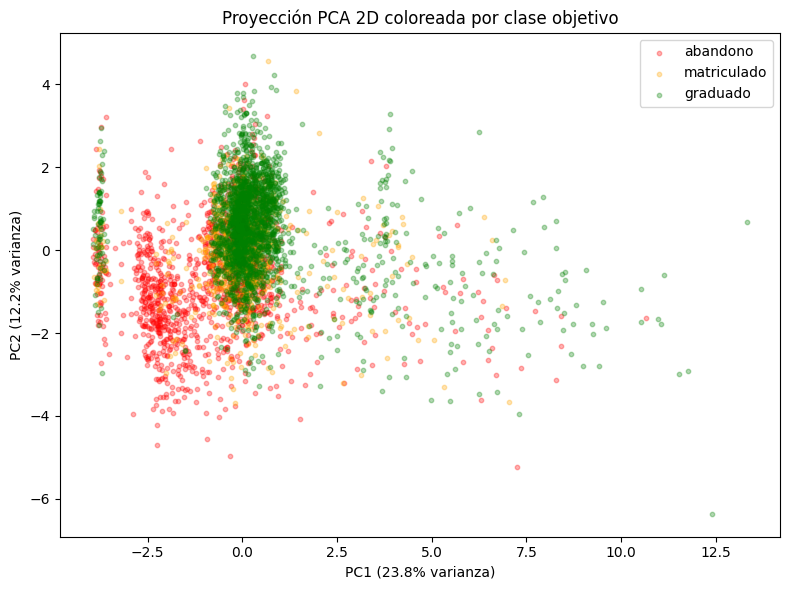

In [6]:
#PCA con 2 componentes para visualización
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

#gráfico coloreado por clase objetivo
colores = {"abandono": "red", "matriculado": "orange", "graduado": "green"}

plt.figure(figsize=(8, 6))
for clase, color in colores.items():
    mask = df["objetivo"] == clase
    plt.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], 
                c=color, label=clase, alpha=0.3, s=10)

plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} varianza)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} varianza)")
plt.title("Proyección PCA 2D coloreada por clase objetivo")
plt.legend()
plt.tight_layout()
plt.show()

La visualización muestra si hay zonas diferenciadas por clase. No espero una separación perfecta, pero si se ven tendencias, eso indica que la estructura capturada por PCA tiene relación con la trayectoria del estudiante.

**6. Interpretación de las componentes principales**

Para entender qué representan las componentes principales estudio el peso de cada variable original en cada componente.

Los loadings permiten interpretar qué mide cada componente. Si PC1 está dominada por las variables de rendimiento del primer semestre, podemos interpretarla como un eje de desempeño académico temprano.

**7. Elección del número de clusters**

Antes de aplicar clustering, necesito decidir cuántos clusters usar. Utilizo dos criterios: el método del codo (inercia) y el coeficiente de silueta.

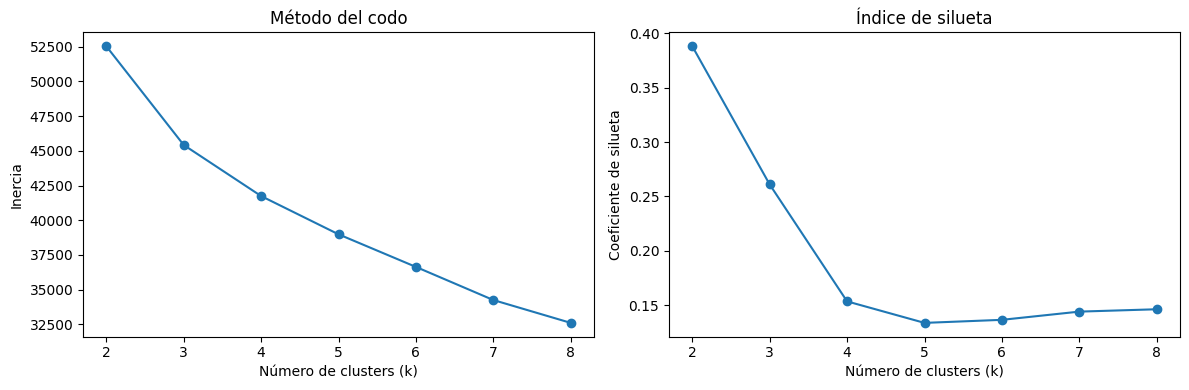

Silueta por k:
  k=2: 0.388
  k=3: 0.261
  k=4: 0.153
  k=5: 0.134
  k=6: 0.136
  k=7: 0.144
  k=8: 0.146


In [7]:
#método del codo e índice de silueta usando la función de src
inercias, siluetas = evaluar_rango_k(X_scaled, 2, 8)
rango_k = range(2, 9)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(rango_k), inercias, marker="o")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia")
axes[0].set_title("Método del codo")

axes[1].plot(list(rango_k), siluetas, marker="o")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].set_title("Índice de silueta")

plt.tight_layout()
plt.show()

print("Silueta por k:")
for k, s in zip(rango_k, siluetas):
    print(f"  k={k}: {s:.3f}")

Analizo ambos gráficos para elegir k. El codo indica el punto en que la reducción de inercia se ralentiza. La silueta mide cuánto se parecen las observaciones a su propio cluster frente a los demás. Un valor más alto indica clusters mejor definidos.

**8. K-Means con el k seleccionado**

Los criterios de clustering indican que la estructura más compacta aparece en k=2, con la silueta más alta (0.388). Sin embargo, también analizo la solución k=3 porque proporciona una división más fina y más útil desde el punto de vista interpretativo. Esto se debe a que me permite distinguir perfiles con matices que k=2 agrupa en un solo bloque. La coincidencia con las tres clases de la variable objetivo no se utiliza como criterio principal de selección, sino únicamente como referencia auxiliar para comparar posteriormente si los grupos encontrados presentan diferencias académicas relevantes.

In [8]:
#k-means con k=3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

df["cluster"] = clusters

print(f"Silueta con k=3: {silhouette_score(X_scaled, clusters):.3f}")

print("\nTamaño de cada cluster: \n", df["cluster"].value_counts().sort_index())

Silueta con k=3: 0.261

Tamaño de cada cluster: 
 cluster
0    3416
1     288
2     720
Name: count, dtype: int64


**9. Visualización de clusters en PCA 2D**

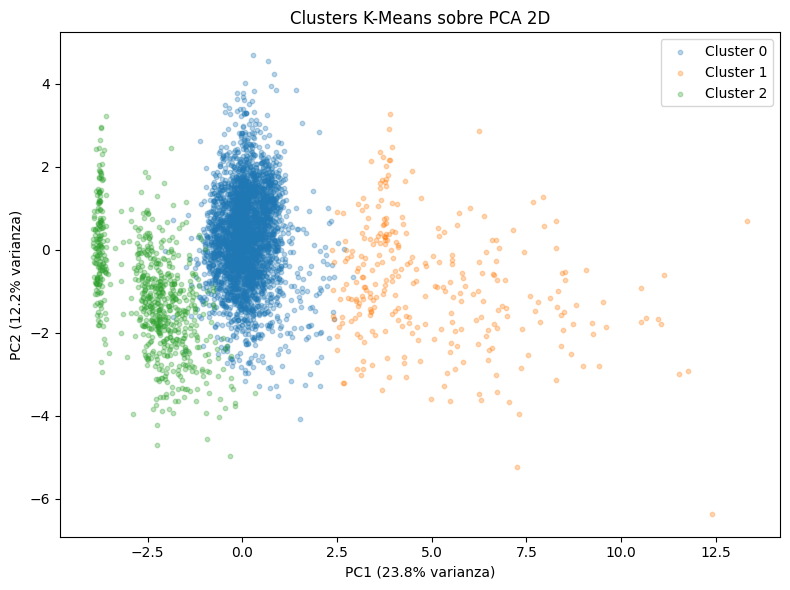

In [9]:
#clusters sobre el PCA 2D
plt.figure(figsize=(8, 6))
for c in sorted(df["cluster"].unique()):
    mask = df["cluster"] == c
    plt.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
                label=f"Cluster {c}", alpha=0.3, s=10)

plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} varianza)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} varianza)")
plt.title("Clusters K-Means sobre PCA 2D")
plt.legend()
plt.tight_layout()
plt.show()

**10. Caracterización de los clusters**

Para que los clusters sean útiles necesito describirlos: qué tipo de estudiante hay en cada uno. Calculo las medias de las variables numéricas y las proporciones de las categóricas por cluster.

In [10]:
#medias de variables numéricas por cluster
vars_describir = vars_numericas_ns + ["nota_media_2sem"]

perfil_numerico = df.groupby("cluster")[vars_describir].mean().round(2)
print("Perfil numérico por cluster:")
perfil_numerico.T

Perfil numérico por cluster:


cluster,0,1,2
edad_al_matricularse,22.25,29.21,25.72
nota_admision,126.80,129.41,126.83
nota_cualificacion_previa,132.67,131.73,132.71
orden_solicitud,1.81,1.14,1.58
asignaturas_1sem_matriculadas,6.14,13.11,4.16
asignaturas_1sem_evaluadas,8.54,16.68,3.82
asignaturas_1sem_aprobadas,5.12,11.51,0.00
nota_media_1sem,12.71,12.63,0.03
asignaturas_1sem_sin_evaluacion,0.09,0.44,0.25
asignaturas_1sem_convalidadas,0.19,8.60,0.00


In [11]:
#proporciones de categóricas por cluster
for var in vars_categoricas_ns:
    print(f"\n--- {var} ---")
    tabla = pd.crosstab(df["cluster"], df[var], normalize="index").round(3) * 100
    print(tabla)


--- genero ---
genero   hombre  mujer
cluster               
0          31.0   69.0
1          36.5   63.5
2          54.3   45.7

--- desplazado ---
desplazado    no    si
cluster               
0           42.6  57.4
1           61.1  38.9
2           51.0  49.0

--- internacional ---
internacional    no   si
cluster                 
0              97.5  2.5
1              97.2  2.8
2              97.5  2.5

--- deudor ---
deudor     no    si
cluster            
0        90.3   9.7
1        84.4  15.6
2        82.2  17.8

--- matricula_al_dia ---
matricula_al_dia    no    si
cluster                     
0                  8.3  91.7
1                 11.1  88.9
2                 29.4  70.6

--- becado ---
becado     no    si
cluster            
0        70.9  29.1
1        88.9  11.1
2        89.7  10.3


**11. Relación entre clusters y variable objetivo**

Ahora cruzo los clusters con la variable objetivo, que no se usó para construirlos. Esto me permite ver si los perfiles descubiertos de forma no supervisada se relacionan con el abandono, la permanencia o la graduación.

Proporcion de cada clase por cluster (%):
objetivo  abandono  graduado  matriculado
cluster                                  
0             22.8      57.1         20.1
1             24.3      62.5         13.2
2             79.4      10.7          9.9


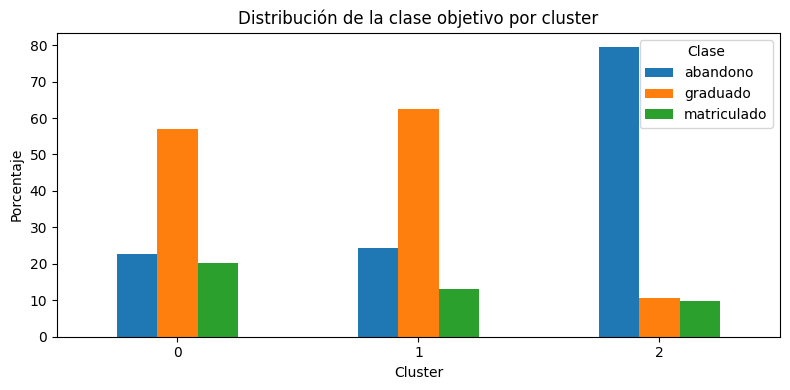

In [12]:
#tabla cruzada clusters vs objetivo
tabla_cruzada = pd.crosstab(df["cluster"], df["objetivo"], normalize="index").round(3) * 100
print("Proporcion de cada clase por cluster (%):")
print(tabla_cruzada)

#gráfico
tabla_cruzada.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Porcentaje")
plt.xlabel("Cluster")
plt.title("Distribución de la clase objetivo por cluster")
plt.legend(title="Clase")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Si un cluster concentra mucho más abandono que los demás, eso indica que ese perfil de estudiante tiene más riesgo. La variable objetivo no se usó para construir los clusters, así que la asociación sale directamente de los datos.

**12. Comparación con clustering jerárquico**

Para evaluar la robustez de los clusters, comparo los resultados de K-Means con un clustering jerárquico aglomerativo usando el mismo k. Si ambos métodos producen agrupaciones similares, los clusters son más fiables.

In [13]:
#clustering jerárquico con k=3
jerarquico = AgglomerativeClustering(n_clusters=3)
clusters_jer = jerarquico.fit_predict(X_scaled)

#tabla cruzada entre ambos métodos
comparacion_metodos = pd.crosstab(
    pd.Series(clusters, name="K-Means"),
    pd.Series(clusters_jer, name="Jerárquico")
)

print("Comparación K-Means vs Jerárquico: \n", comparacion_metodos)

print(f"Silueta K-Means: {silhouette_score(X_scaled, clusters):.3f}"
	  f"\nSilueta Jerárquico: {silhouette_score(X_scaled, clusters_jer):.3f}")

Comparación K-Means vs Jerárquico: 
 Jerárquico     0    1    2
K-Means                   
0           3376   39    1
1             13  275    0
2             35    0  685
Silueta K-Means: 0.261
Silueta Jerárquico: 0.242


**13. Análisis de estabilidad básico**

El material del curso advierte que el clustering puede no ser robusto a pequeñas perturbaciones. Para comprobar la estabilidad de los clusters, repito el K-Means en varias submuestras aleatorias del 80% de los datos y comparo las siluetas obtenidas.

In [14]:
#estabilidad usando la función de src
siluetas_submuestras = analisis_estabilidad(X_scaled, k=3, n_repeticiones=10)

print("Silueta en 10 submuestras (80%):")
for i, s in enumerate(siluetas_submuestras):
    print(f"  Submuestra {i}: {s:.3f}")

print(f"\nMedia: {np.mean(siluetas_submuestras):.3f}"
      f"\nDesviación: {np.std(siluetas_submuestras):.3f}")

Silueta en 10 submuestras (80%):
  Submuestra 0: 0.261
  Submuestra 1: 0.260
  Submuestra 2: 0.261
  Submuestra 3: 0.260
  Submuestra 4: 0.260
  Submuestra 5: 0.262
  Submuestra 6: 0.263
  Submuestra 7: 0.262
  Submuestra 8: 0.261
  Submuestra 9: 0.259

Media: 0.261
Desviación: 0.001


Si la silueta se mantiene estable entre submuestras (desviación pequeña), los clusters no dependen de observaciones concretas y son razonablemente robustos.

**14. Interpretación de resultados del aprendizaje no supervisado**

A continuación, se presenta un resumen de las conclusiones principales de la tarea no supervisada.

He trabajado con un subconjunto de 19 variables que combina perfil del estudiante, situación administrativa, rendimiento del primer semestre y contexto macroeconómico. Por otro lado, he dejado fuera las variables de alta cardinalidad (ocupación, nacionalidad, cualificación) para que no dominaran el análisis tras el one-hot encoding.

La primera componente principal (23.8% de varianza) está dominada por las variables de rendimiento del primer semestre: asignaturas matriculadas, aprobadas y evaluadas. Se puede interpretar como un eje de desempeño académico temprano.

El clustering con K-Means (k=3) identifica tres perfiles diferenciados. El cluster 0 (3416 estudiantes) tiene rendimiento medio-alto y concentra la mayoría de graduados. El cluster 1 (288 estudiantes) corresponde a estudiantes con muchas convalidaciones. El cluster 2 (720 estudiantes) tiene rendimiento nulo en el primer semestre y concentra el 79.4% de los abandonos.

No he usado la variable objetivo para construir los clusters, por lo que la asociación entre el cluster 2 y el abandono es únicamente cuestión de la estructura de los datos. Este perfil de riesgo es detectable al final del primer semestre.

La comparación con clustering jerárquico muestra un solapamiento alto entre ambos métodos, y el análisis de estabilidad en 10 submuestras da una silueta media de 0.261 con desviación de 0.001. Los clusters son razonablemente estables, aunque la silueta moderada indica que la separación entre grupos no es nítida.

**15. Limpieza**

Elimino la columna de cluster del dataframe para dejarlo limpio.

In [15]:
df = df.drop(columns=["cluster"])